In [1]:
import glob
import os
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay


In [2]:
from google.colab import drive
drive.mount('/content/drive')

SCRIPT_DIR = "/content/drive/MyDrive/Datasets"
SCRIPT_DIR = SCRIPT_DIR.rstrip(os.sep) + os.sep

DATASET_DIR = os.path.join(SCRIPT_DIR.rstrip(os.sep), "Monitor_Dataset")
SHIMMER_DIR = os.path.join(DATASET_DIR, "shimmer")
QUESTIONNAIRE_DIR = os.path.join(
    DATASET_DIR, "MONITOR Questionnaire and Response Dataset with Test Subject Info"
)

print("SCRIPT_DIR:", SCRIPT_DIR)
print("SHIMMER_DIR exists:", os.path.isdir(SHIMMER_DIR))

Mounted at /content/drive
SCRIPT_DIR: /content/drive/MyDrive/Datasets/
SHIMMER_DIR exists: True


In [3]:
def all_data_csv(base_path, output_csv=None):
    combined_df = pd.DataFrame()

    subject_dirs = sorted(
        d for d in os.listdir(base_path)
        if os.path.isdir(os.path.join(base_path, d)) and d.startswith("C")
    )

    for subject in tqdm(subject_dirs, desc="Processing Subjects"):
        subject_path = os.path.join(base_path, subject)

        for session, label in [("base", 0), ("stress_induced", 1)]:
            pattern = os.path.join(subject_path, f"{subject}_*_{session}.csv")
            files = glob.glob(pattern)
            if not files:
                continue

            df = pd.read_csv(files[0])
            if "Heart Rate Ear(BPM)" in df.columns:
                df = df.rename(columns={"Heart Rate Ear(BPM)": "HeartRate"})
            if "HeartRate" not in df.columns or "GSR" not in df.columns:
                continue

            df = df[["HeartRate", "GSR"]].copy()
            df.replace(0, np.nan, inplace=True)
            df.fillna(df.median(), inplace=True)
            df["label"] = label
            combined_df = pd.concat([combined_df, df], ignore_index=True)

    if output_csv:
        combined_df.to_csv(output_csv, index=False)
    print("Final shape:", combined_df.shape)
    return combined_df



Pre-Processing

In [4]:
def calculate_eda_value(gsr_value):
    resistance = ((1024 + 2 * gsr_value) * 10000) / (512 - gsr_value)
    eda_value = (1 / resistance) * 1e6
    return eda_value


def preprocess_monitor_data(df):
    df = df[df["GSR"] < 512].copy()
    df["EDA"] = df["GSR"].apply(calculate_eda_value)
    df = df.drop(columns=["GSR"])
    df = df[(df["HeartRate"] > 40) & (df["HeartRate"] < 180)]

    if "label" in df.columns:
        num_cols = [c for c in df.columns if c != "label"]
        df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    else:
        df = df.fillna(df.median())

    df["HeartRate"] = df["HeartRate"].rolling(5).mean()
    df["EDA"] = df["EDA"].rolling(5).mean()
    df = df.dropna()

    for col in ["HeartRate", "EDA"]:
        if col in df.columns:
            s = df[col].std()
            if s and s > 0:
                df[col] = (df[col] - df[col].mean()) / s

    return df

Extraction Features

In [5]:

def statistical_features(arr):
    return np.min(arr), np.max(arr), np.mean(arr), np.std(arr)


def shape_features(arr):
    return skew(arr), kurtosis(arr)


def calculate_rms(signal):
    return np.sqrt(np.mean(np.square(np.ediff1d(signal))))


def extract_features(signal):
    vmin, vmax, mean, std = statistical_features(signal)
    sk, kt = shape_features(signal)
    rms = calculate_rms(signal)
    return [vmin, vmax, mean, std, sk, kt, rms]


def extract_monitor_features(df, window_size=60):
    cols = [
        "HR_min", "HR_max", "HR_mean", "HR_std", "HR_skew", "HR_kurtosis", "HR_rms",
        "EDA_min", "EDA_max", "EDA_mean", "EDA_std", "EDA_skew", "EDA_kurtosis", "EDA_rms",
        "label",
    ]
    if len(df) < window_size:
        if len(df) < 5:
            return pd.DataFrame(columns=cols)
        windows = [df]
    else:
        windows = [df.iloc[i : i + window_size] for i in range(0, len(df) - window_size + 1)]

    rows = []
    for w in windows:
        hr_f = extract_features(w["HeartRate"].values)
        eda_f = extract_features(w["EDA"].values)
        lab = w["label"].iloc[-1]
        rows.append(hr_f + eda_f + [lab])

    return pd.DataFrame(rows, columns=cols)

In [6]:
def preprocess_questionnaire_stress(
    questionnaire_dir,
    *,
    include_baseline_stress=True,
    include_demographics=False,
):
    """
    Preprocess MONITOR questionnaire data for predicting stress-induced
    perceived stress from baseline questionnaire answers.

    Returns
    -------
    X : pd.DataFrame
        Features (38 baseline questions + optional baseline_stress + optional demographics).
    y : pd.Series
        Target: stress-induced "How stressed have you been?" (1-10).
    meta : pd.DataFrame
        ID, stress_induced, baseline_stress, stress_similar (for reference/export).
    """
    base = pd.read_csv(os.path.join(questionnaire_dir, "_baseline score.csv"))
    stress = pd.read_csv(os.path.join(questionnaire_dir, "_stressed_induced score.csv"))
    info = pd.read_csv(os.path.join(questionnaire_dir, "_test subject info.csv"))

    m = base.merge(
        stress,
        on="ID",
        how="inner",
        suffixes=("_baseline", "_induced"),
    )

    y = m["How stressed have you been?_induced"].copy()

    q_cols = [
        c for c in base.columns
        if c not in ("ID", "How stressed have you been?")
    ]
    X = m[q_cols].copy()

    if include_baseline_stress:
        X["baseline_stress"] = m["How stressed have you been?_baseline"].values

    if include_demographics:
        m_info = m.merge(
            info,
            left_on="ID",
            right_on="Test Subject ID",
            how="left",
        )
        dums = pd.get_dummies(
            m_info[["Age Group", "Gender", "Marital Status", "Job Role"]],
            drop_first=True,
        )
        exp_cols = [
            "Year of experience in the current role",
            "Year of experience in the RMG Sector",
        ]
        X = pd.concat([X, dums, m_info[exp_cols]], axis=1)

    X = X.fillna(X.median(numeric_only=True))

    meta = pd.DataFrame({
        "ID": m["ID"].values,
        "stress_induced": m["How stressed have you been?_induced"].values,
        "baseline_stress": m["How stressed have you been?_baseline"].values,
        "stress_similar": m["How similar stress do you feel in a stressed working environment compared to todays experiment?"].values,
    })

    return X, y, meta

In [7]:
combined = all_data_csv(
    SHIMMER_DIR,
    output_csv=os.path.join(SCRIPT_DIR, "monitor_ml_dataset.csv"),
)
df = preprocess_monitor_data(combined)
df.to_csv(os.path.join(SCRIPT_DIR, "monitor_preprocessed.csv"), index=False)

df_features = extract_monitor_features(df)
print(df_features.shape)
print(df_features.head())

df_features.to_csv(os.path.join(SCRIPT_DIR, "monitor_features.csv"), index=False)

Processing Subjects: 100%|██████████| 24/24 [00:18<00:00,  1.29it/s]


Final shape: (35883, 3)


/tmp/ipython-input-1799780286.py:6: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  return skew(arr), kurtosis(arr)


(23385, 15)
     HR_min    HR_max   HR_mean    HR_std   HR_skew  HR_kurtosis    HR_rms  \
0 -0.799744  0.643844  0.059727  0.332081 -0.412433    -0.146811  0.129742   
1 -0.799744  0.643844  0.049199  0.324213 -0.429921    -0.065681  0.130515   
2 -0.799744  0.643844  0.040721  0.317791 -0.438797     0.030974  0.128865   
3 -0.799744  0.643844  0.037132  0.315191 -0.434714     0.090696  0.129916   
4 -0.799744  0.643844  0.034900  0.313218 -0.438573     0.135715  0.130260   

    EDA_min   EDA_max  EDA_mean   EDA_std  EDA_skew  EDA_kurtosis   EDA_rms  \
0 -1.572519 -1.080418 -1.371342  0.144633  0.394765     -1.172529  0.031410   
1 -1.572519 -1.080418 -1.376006  0.143813  0.465691     -1.096574  0.031391   
2 -1.572519 -1.080418 -1.380706  0.142502  0.538472     -0.997537  0.031213   
3 -1.572519 -1.080418 -1.384859  0.139918  0.600927     -0.864484  0.031676   
4 -1.572519 -1.080418 -1.388518  0.135943  0.622692     -0.756242  0.032840   

   label  
0      0  
1      0  
2      0  


Saved: /content/drive/MyDrive/Datasets/report_figures/00_sample_signals.png


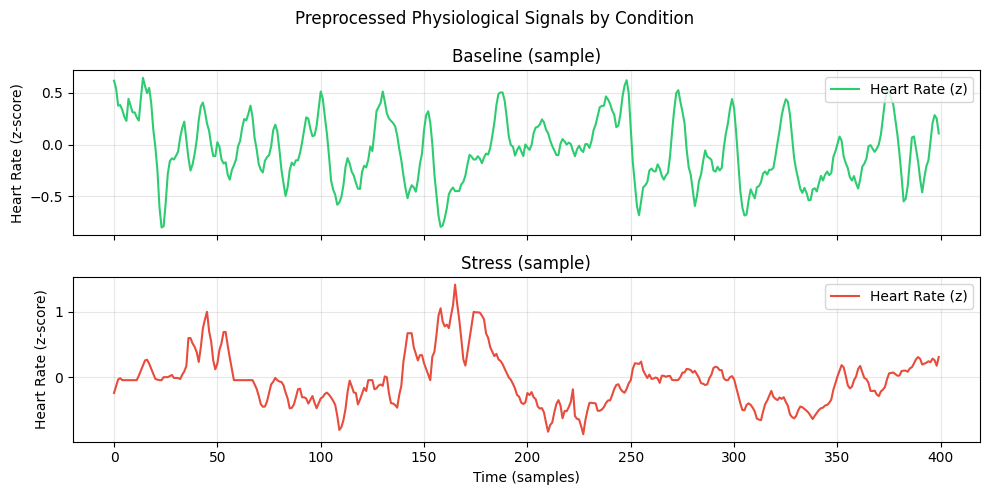

Saved: /content/drive/MyDrive/Datasets/report_figures/01_class_distribution.png


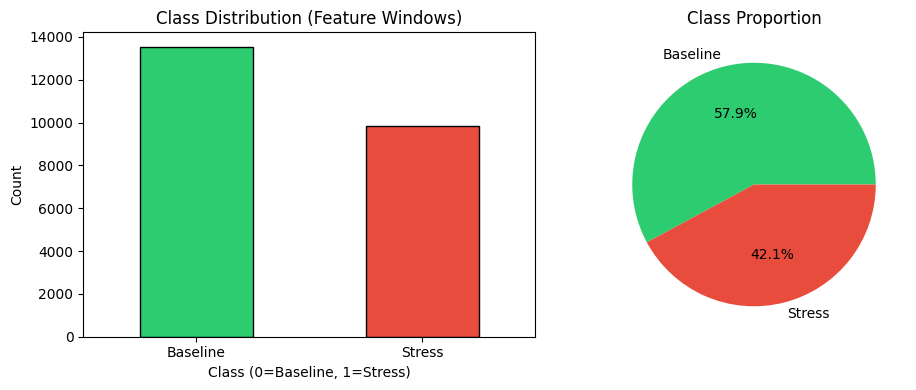

Saved: /content/drive/MyDrive/Datasets/report_figures/02_features_by_class.png


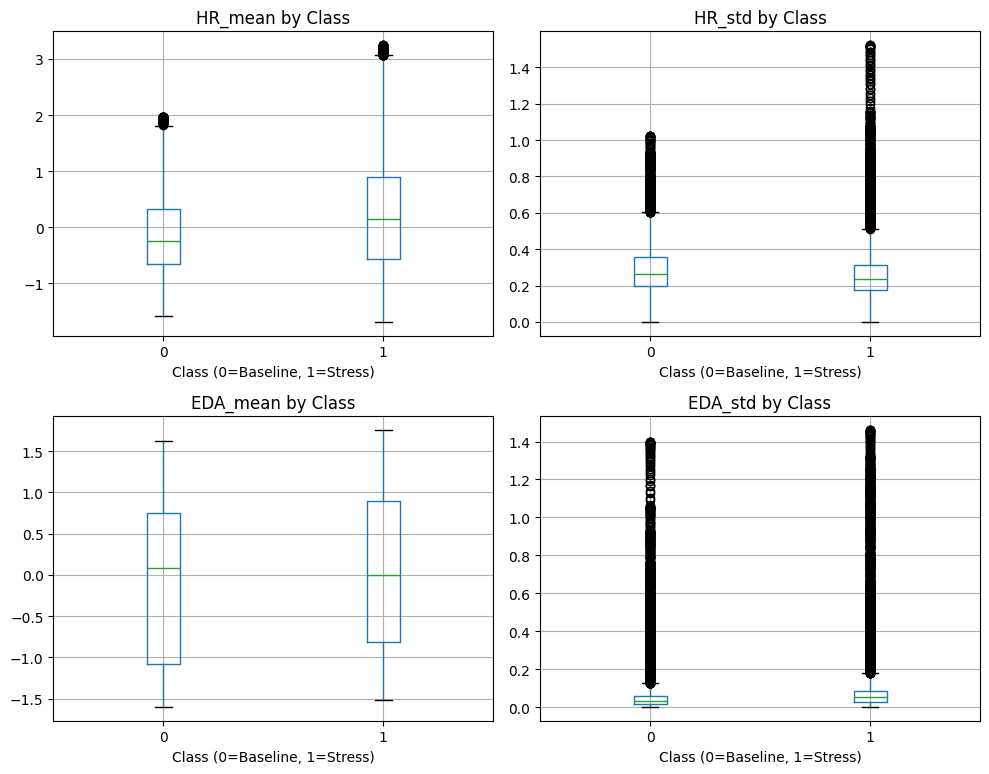

Saved: /content/drive/MyDrive/Datasets/report_figures/03_feature_correlation.png


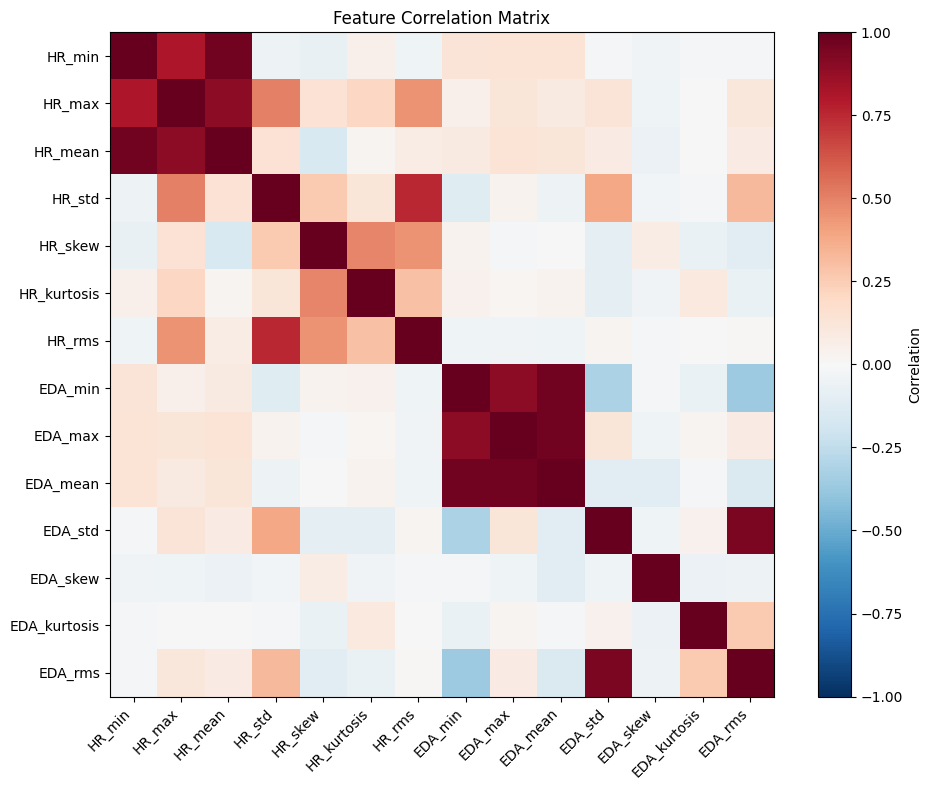

In [8]:
# Optional: folder to save figures for your report (set to None to only display)
FIG_DIR = os.path.join(SCRIPT_DIR, "report_figures")
if FIG_DIR and not os.path.exists(FIG_DIR):
    os.makedirs(FIG_DIR)

def save_fig(name):
    """Save current figure for report if FIG_DIR is set."""
    if FIG_DIR:
        path = os.path.join(FIG_DIR, name)
        plt.savefig(path, dpi=150, bbox_inches="tight")
        print(f"Saved: {path}")

# --- 0. Sample preprocessed signals (Baseline vs Stress) ---
n_sample = 400
df_b = df[df["label"] == 0].head(n_sample)
df_s = df[df["label"] == 1].head(n_sample)
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(df_b["HeartRate"].values, label="Heart Rate (z)", color="#2ecc71")
axes[0].set_ylabel("Heart Rate (z-score)")
axes[0].set_title("Baseline (sample)")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)
axes[1].plot(df_s["HeartRate"].values, label="Heart Rate (z)", color="#e74c3c")
axes[1].set_xlabel("Time (samples)")
axes[1].set_ylabel("Heart Rate (z-score)")
axes[1].set_title("Stress (sample)")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)
plt.suptitle("Preprocessed Physiological Signals by Condition")
plt.tight_layout()
save_fig("00_sample_signals.png")
plt.show()

# --- 1. Class distribution ---
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df_features["label"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#2ecc71", "#e74c3c"], edgecolor="black")
ax[0].set_xlabel("Class (0=Baseline, 1=Stress)")
ax[0].set_ylabel("Count")
ax[0].set_title("Class Distribution (Feature Windows)")
ax[0].set_xticklabels(["Baseline", "Stress"], rotation=0)
df_features["label"].value_counts().plot(kind="pie", ax=ax[1], autopct="%1.1f%%", labels=["Baseline", "Stress"], colors=["#2ecc71", "#e74c3c"])
ax[1].set_ylabel("")
ax[1].set_title("Class Proportion")
plt.tight_layout()
save_fig("01_class_distribution.png")
plt.show()

# --- 2. Key features by class (boxplots) ---
feature_cols = [c for c in df_features.columns if c != "label"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()
for i, col in enumerate(["HR_mean", "HR_std", "EDA_mean", "EDA_std"]):
    if col in df_features.columns:
        df_features.boxplot(column=col, by="label", ax=axes[i])
        axes[i].set_title(f"{col} by Class")
        axes[i].set_xlabel("Class (0=Baseline, 1=Stress)")
plt.suptitle("")
plt.tight_layout()
save_fig("02_features_by_class.png")
plt.show()

# --- 3. Correlation heatmap of features ---
corr = df_features[feature_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)))
ax.set_yticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=45, ha="right")
ax.set_yticklabels(feature_cols)
plt.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
save_fig("03_feature_correlation.png")
plt.show()

In [9]:
qX, qy, qmeta = preprocess_questionnaire_stress(
    QUESTIONNAIRE_DIR,
    include_baseline_stress=True,
    include_demographics=False,
)
qX.to_csv(os.path.join(SCRIPT_DIR, "questionnaire_X.csv"), index=False)
qy.to_csv(os.path.join(SCRIPT_DIR, "questionnaire_y.csv"), index=False)
q_preprocessed = pd.concat([qmeta[["ID", "stress_induced", "stress_similar"]], qX], axis=1)
q_preprocessed.to_csv(os.path.join(SCRIPT_DIR, "questionnaire_preprocessed.csv"), index=False)
print("Questionnaire stress-preprocessed: X", qX.shape, "y", qy.shape)

Questionnaire stress-preprocessed: X (24, 39) y (24,)


*Stress* detection- Regression model

In [10]:

# Load regression dataset

SCRIPT_DIR = "/content/drive/MyDrive/Datasets/"
data_r = pd.read_csv(SCRIPT_DIR + "monitor_features.csv")

# Features and labels (14 features: columns 0-13, label: column 14)
X_r = data_r.iloc[:, 0:14]
y_r = data_r.iloc[:, 14]

# Train-validation split
X_train_r, X_val_r, y_train_r, y_val_r = train_test_split(
    X_r, y_r, test_size=0.33, random_state=30
)

# Train regression model
stress_regressor = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=30
)
stress_regressor.fit(X_train_r, y_train_r)

# Prediction
y_pred_r = stress_regressor.predict(X_val_r)

# Evaluation
r2 = r2_score(y_val_r, y_pred_r)
print("Regression R² Score:", r2)


Regression R² Score: 0.9786945370853546


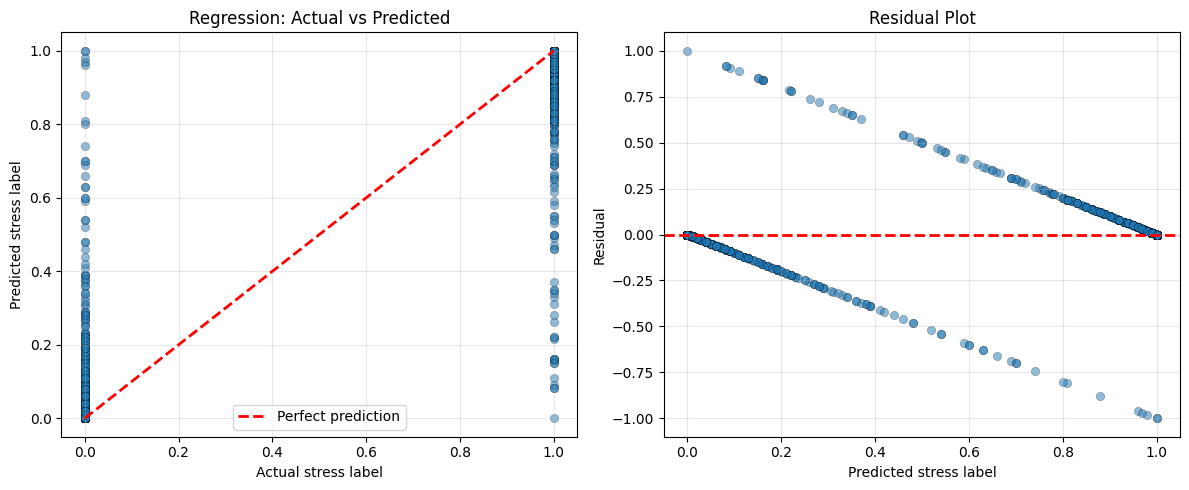

In [11]:
# Regression: Actual vs Predicted and Residuals (for report)
FIG_DIR = os.path.join(SCRIPT_DIR, "report_figures") if 'SCRIPT_DIR' in dir() else None
if FIG_DIR and not os.path.exists(FIG_DIR):
    os.makedirs(FIG_DIR)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_val_r, y_pred_r, alpha=0.5, edgecolors="k", linewidth=0.3)
max_val = max(y_val_r.max(), y_pred_r.max())
min_val = min(y_val_r.min(), y_pred_r.min())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect prediction")
axes[0].set_xlabel("Actual stress label")
axes[0].set_ylabel("Predicted stress label")
axes[0].set_title("Regression: Actual vs Predicted")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
residuals = y_val_r - y_pred_r
axes[1].scatter(y_pred_r, residuals, alpha=0.5, edgecolors="k", linewidth=0.3)
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_xlabel("Predicted stress label")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residual Plot")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
if FIG_DIR:
    plt.savefig(os.path.join(FIG_DIR, "04_regression_actual_vs_predicted.png"), dpi=150, bbox_inches="tight")
plt.show()

Stress Detection – Classification Model

In [12]:


# Load classification dataset
SCRIPT_DIR = "/content/drive/MyDrive/Datasets/"
data_c = pd.read_csv(SCRIPT_DIR + "monitor_features.csv")

# Features and labels (14 features: columns 0-13, label: column 14)
X_c = data_c.iloc[:, 0:14]
y_c = data_c.iloc[:, 14]

# Train-validation split
X_train_c, X_val_c, y_train_c, y_val_c = train_test_split(
    X_c, y_c, test_size=0.33, random_state=30
)

# Train classification model
stress_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=30
)
stress_classifier.fit(X_train_c, y_train_c)

# Prediction
y_pred_c = stress_classifier.predict(X_val_c)


Classification evaluation

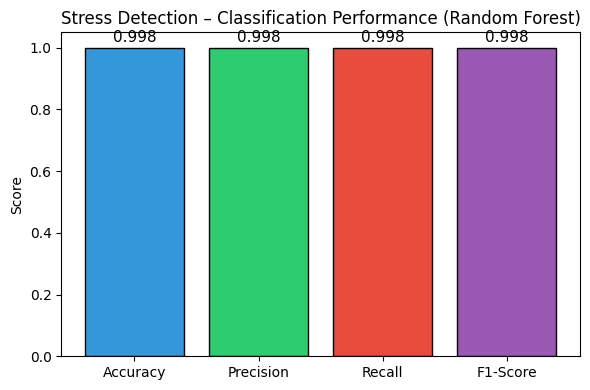

In [13]:
# Classification metrics bar chart (for report)
accuracy = accuracy_score(y_val_c, y_pred_c)
precision = precision_score(y_val_c, y_pred_c, average='macro', zero_division=0)
recall = recall_score(y_val_c, y_pred_c, average='macro')
f1 = f1_score(y_val_c, y_pred_c, average='macro')
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values = [accuracy, precision, recall, f1]
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(metrics, values, color=["#3498db", "#2ecc71", "#e74c3c", "#9b59b6"], edgecolor="black")
ax.set_ylabel("Score")
ax.set_title("Stress Detection – Classification Performance (Random Forest)")
ax.set_ylim(0, 1.05)
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f"{v:.3f}", ha="center", fontsize=11)
plt.tight_layout()
FIG_DIR = os.path.join(SCRIPT_DIR, "report_figures") if 'SCRIPT_DIR' in dir() else None
if FIG_DIR:
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.savefig(os.path.join(FIG_DIR, "05_classification_metrics.png"), dpi=150, bbox_inches="tight")
plt.show()

In [14]:
accuracy  = accuracy_score(y_val_c, y_pred_c)
precision = precision_score(y_val_c, y_pred_c, average='macro', zero_division=0)
recall    = recall_score(y_val_c, y_pred_c, average='macro')
f1        = f1_score(y_val_c, y_pred_c, average='macro')

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)


Accuracy : 0.9976677895827935
Precision: 0.9976009772645089
Recall   : 0.9976009772645089
F1-score : 0.9976009772645089


Confusion Matrix

## Model Comparison - Multiple Algorithms

Comparing different models to find the best approach for stress detection.

In [15]:
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score, classification_report
import warnings
warnings.filterwarnings('ignore')

# Load data
SCRIPT_DIR = "/content/drive/MyDrive/Datasets/"
data = pd.read_csv(SCRIPT_DIR + "monitor_features.csv")

X = data.iloc[:, 0:14]
y = data.iloc[:, 14]

# Handle NaN values before splitting
print("Checking for NaN values...")
print(f"NaN count in X: {X.isna().sum().sum()}")
if X.isna().sum().sum() > 0:
    print("Filling NaN values with median...")
    X = X.fillna(X.median())
print(f"NaN count after handling: {X.isna().sum().sum()}\n")

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=30
)

# Ensure no NaN values in train/test sets
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())  # Use training median for test set

print("Dataset shape:", X.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print(f"NaN count in X_train: {X_train.isna().sum().sum()}")
print(f"NaN count in X_test: {X_test.isna().sum().sum()}")
print("\nClass distribution:")
print(y.value_counts())

Checking for NaN values...
NaN count in X: 158
Filling NaN values with median...
NaN count after handling: 0

Dataset shape: (23385, 14)
Training set: (15667, 14)
Test set: (7718, 14)
NaN count in X_train: 0
NaN count in X_test: 0

Class distribution:
label
0    13536
1     9849
Name: count, dtype: int64


### Classification Models Comparison

<Figure size 500x500 with 0 Axes>

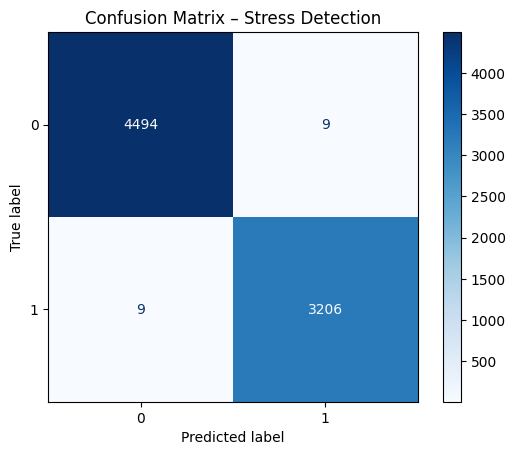

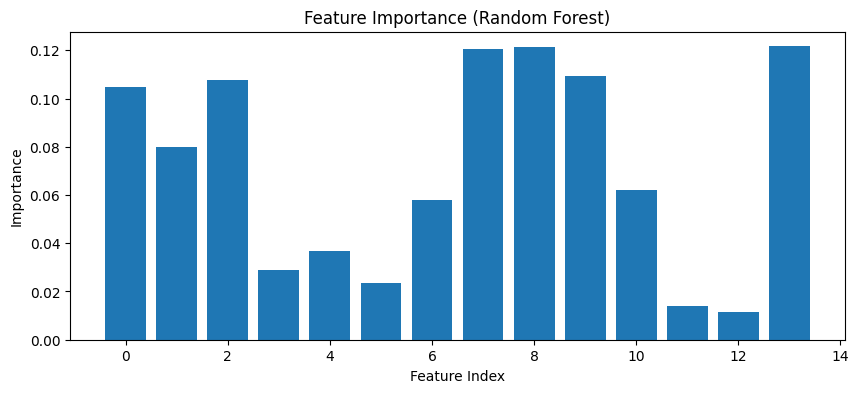

In [16]:
FIG_DIR = os.path.join(SCRIPT_DIR, "report_figures") if 'SCRIPT_DIR' in dir() else None
if FIG_DIR:
    os.makedirs(FIG_DIR, exist_ok=True)
plt.figure(figsize=(5,5))
ConfusionMatrixDisplay.from_predictions(
    y_val_c,
    y_pred_c,
    cmap="Blues"
)
plt.title("Confusion Matrix – Stress Detection")
if FIG_DIR:
    plt.savefig(os.path.join(FIG_DIR, "06_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

importances = stress_classifier.feature_importances_

plt.figure(figsize=(10,4))
plt.bar(range(len(importances)), importances)
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.title("Feature Importance (Random Forest)")
if FIG_DIR:
    plt.savefig(os.path.join(FIG_DIR, "07_feature_importance.png"), dpi=150, bbox_inches="tight")
plt.show()

# Explicit Stress Detection Function
def stress_detection_model(input_features):
    """
    Predict stress level:
    0 = Low, 1 = Medium, 2 = High
    """
    return stress_classifier.predict(input_features)


In [17]:
# Ensure no NaN values (safety check)
if X_train.isna().sum().sum() > 0 or X_test.isna().sum().sum() > 0:
    X_train = X_train.fillna(X_train.median())
    X_test = X_test.fillna(X_train.median())

# Define classification models
classification_models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=15, random_state=30),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=30),
    'SVM (RBF)': SVC(kernel='rbf', random_state=30),
    'SVM (Linear)': SVC(kernel='linear', random_state=30),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(max_depth=15, random_state=30),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=30)
}

# Evaluate classification models
classification_results = []

print("=" * 80)
print("CLASSIFICATION MODELS COMPARISON")
print("=" * 80)

for name, model in classification_models.items():
    # Train model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    # Cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

    results = {
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std()
    }

    classification_results.append(results)

    print(f"\n{name}:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-Score:  {f1:.4f}")
    print(f"  CV Score:  {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

# Create comparison DataFrame
df_classification = pd.DataFrame(classification_results)
df_classification = df_classification.sort_values('Accuracy', ascending=False)

print("\n" + "=" * 80)
print("RANKED RESULTS (by Accuracy)")
print("=" * 80)
print(df_classification.to_string(index=False))

CLASSIFICATION MODELS COMPARISON

Random Forest:
  Accuracy:  0.9978
  Precision: 0.9977
  Recall:    0.9978
  F1-Score:  0.9977
  CV Score:  0.9983 (+/- 0.0011)

Logistic Regression:
  Accuracy:  0.6886
  Precision: 0.6806
  Recall:    0.6663
  F1-Score:  0.6687
  CV Score:  0.6891 (+/- 0.0089)

SVM (RBF):
  Accuracy:  0.7709
  Precision: 0.7753
  Recall:    0.7487
  F1-Score:  0.7546
  CV Score:  0.7594 (+/- 0.0144)

SVM (Linear):
  Accuracy:  0.6914
  Precision: 0.6970
  Recall:    0.6554
  F1-Score:  0.6549
  CV Score:  0.6925 (+/- 0.0081)

K-Nearest Neighbors:
  Accuracy:  0.9708
  Precision: 0.9713
  Recall:    0.9687
  F1-Score:  0.9699
  CV Score:  0.9639 (+/- 0.0065)

Naive Bayes:
  Accuracy:  0.6433
  Precision: 0.6388
  Recall:    0.6010
  F1-Score:  0.5922
  CV Score:  0.6435 (+/- 0.0082)

Decision Tree:
  Accuracy:  0.9920
  Precision: 0.9918
  Recall:    0.9916
  F1-Score:  0.9917
  CV Score:  0.9895 (+/- 0.0022)

Neural Network:
  Accuracy:  0.9788
  Precision: 0.9795
  

### Regression Models Comparison

In [18]:
# Define regression models
regression_models = {
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=15, random_state=30),
    'Ridge Regression': Ridge(alpha=1.0, random_state=30),
    'SVR (RBF)': SVR(kernel='rbf'),
    'SVR (Linear)': SVR(kernel='linear'),
    'K-Nearest Neighbors': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(max_depth=15, random_state=30),
    'Neural Network': MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=500, random_state=30)
}

# Evaluate regression models
regression_results = []

print("=" * 80)
print("REGRESSION MODELS COMPARISON")
print("=" * 80)

for name, model in regression_models.items():
    # Train model
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Metrics
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    # Cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')

    results = {
        'Model': name,
        'R² Score': r2,
        'MAE': mae,
        'RMSE': rmse,
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std()
    }

    regression_results.append(results)

    print(f"\n{name}:")
    print(f"  R² Score:  {r2:.4f}")
    print(f"  MAE:       {mae:.4f}")
    print(f"  RMSE:      {rmse:.4f}")
    print(f"  CV Score:  {cv_scores.mean():.4f} (+/- {cv_scores.std()*2:.4f})")

# Create comparison DataFrame
df_regression = pd.DataFrame(regression_results)
df_regression = df_regression.sort_values('R² Score', ascending=False)

print("\n" + "=" * 80)
print("RANKED RESULTS (by R² Score)")
print("=" * 80)
print(df_regression.to_string(index=False))

REGRESSION MODELS COMPARISON

Random Forest:
  R² Score:  0.9787
  MAE:       0.0141
  RMSE:      0.0719
  CV Score:  0.9791 (+/- 0.0044)

Ridge Regression:
  R² Score:  0.1639
  MAE:       0.4123
  RMSE:      0.4508
  CV Score:  0.1716 (+/- 0.0064)

SVR (RBF):
  R² Score:  0.3991
  MAE:       0.2775
  RMSE:      0.3822
  CV Score:  0.3880 (+/- 0.0280)

SVR (Linear):
  R² Score:  0.0737
  MAE:       0.3878
  RMSE:      0.4745
  CV Score:  0.0807 (+/- 0.0220)

K-Nearest Neighbors:
  R² Score:  0.9118
  MAE:       0.0414
  RMSE:      0.1464
  CV Score:  0.8936 (+/- 0.0097)

Decision Tree:
  R² Score:  0.9669
  MAE:       0.0080
  RMSE:      0.0896
  CV Score:  0.9582 (+/- 0.0074)

Neural Network:
  R² Score:  0.9030
  MAE:       0.1013
  RMSE:      0.1536
  CV Score:  0.8966 (+/- 0.0254)

RANKED RESULTS (by R² Score)
              Model  R² Score      MAE     RMSE  CV Mean   CV Std
      Random Forest  0.978702 0.014058 0.071946 0.979089 0.002184
      Decision Tree  0.966947 0.008033 0.

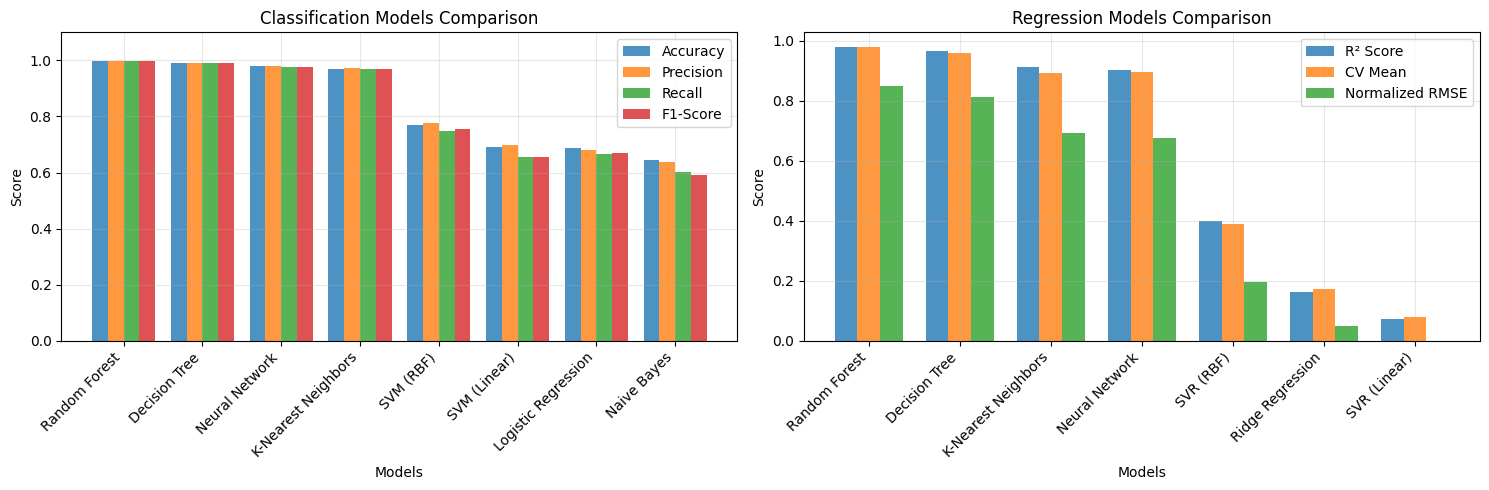


BEST CLASSIFICATION MODEL: Random Forest
  Accuracy: 0.9978

BEST REGRESSION MODEL: Random Forest
  R² Score: 0.9787


In [19]:
# Visualize classification results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Classification metrics
ax1 = axes[0]
x_pos = np.arange(len(df_classification))
width = 0.2

ax1.bar(x_pos - width*1.5, df_classification['Accuracy'], width, label='Accuracy', alpha=0.8)
ax1.bar(x_pos - width*0.5, df_classification['Precision'], width, label='Precision', alpha=0.8)
ax1.bar(x_pos + width*0.5, df_classification['Recall'], width, label='Recall', alpha=0.8)
ax1.bar(x_pos + width*1.5, df_classification['F1-Score'], width, label='F1-Score', alpha=0.8)

ax1.set_xlabel('Models')
ax1.set_ylabel('Score')
ax1.set_title('Classification Models Comparison')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(df_classification['Model'], rotation=45, ha='right')
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0, 1.1])

# Regression metrics
ax2 = axes[1]
x_pos = np.arange(len(df_regression))
width = 0.25

ax2.bar(x_pos - width, df_regression['R² Score'], width, label='R² Score', alpha=0.8)
ax2.bar(x_pos, df_regression['CV Mean'], width, label='CV Mean', alpha=0.8)
ax2.bar(x_pos + width, 1 - df_regression['RMSE']/df_regression['RMSE'].max(), width, label='Normalized RMSE', alpha=0.8)

ax2.set_xlabel('Models')
ax2.set_ylabel('Score')
ax2.set_title('Regression Models Comparison')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(df_regression['Model'], rotation=45, ha='right')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
FIG_DIR = os.path.join(SCRIPT_DIR, "report_figures") if 'SCRIPT_DIR' in dir() else None
if FIG_DIR:
    os.makedirs(FIG_DIR, exist_ok=True)
    plt.savefig(os.path.join(FIG_DIR, "08_models_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

# Print best models
print("\n" + "=" * 80)
print("BEST CLASSIFICATION MODEL:", df_classification.iloc[0]['Model'])
print("  Accuracy:", f"{df_classification.iloc[0]['Accuracy']:.4f}")
print("\nBEST REGRESSION MODEL:", df_regression.iloc[0]['Model'])
print("  R² Score:", f"{df_regression.iloc[0]['R² Score']:.4f}")
print("=" * 80)